# Esercitazione Pratica: "Model Swapping" (Sostituzione dell'Architettura)

## Contesto

Avete appena analizzato lo script che utilizza **MobileNetV2** per classificare un'immagine. MobileNet è ottima per dispositivi mobili perché è leggera, ma a volte abbiamo bisogno di reti più "potenti" o semplicemente diverse per confrontare i risultati.

In questo esercizio, metterete le mani "sotto il cofano" del codice appena visto. Dovrete sostituire il "cervello" (il modello neurale) con una delle architetture più famose della storia della Computer Vision: la **VGG16**.

## Obiettivo

Modificare lo script Python fornito nell'esempio per:

1. Utilizzare l'architettura **VGG16** al posto di MobileNetV2.
2. Cambiare l'immagine di input (scegliete un soggetto diverso da una fragola).
3. Visualizzare le **Top-5** predizioni invece delle Top-3.

---

## Istruzioni Passo-Passo

**1. Modifica delle importazioni (Attenzione!)**

Il primo passo è cambiare le librerie che state importando.

- **Task**: Trovate all'interno di `tensorflow.keras.applications` il modulo per **VGG16**.
- **Importante**: Ogni rete ha il suo metodo `preprocess_input`. Non potete usare quello di MobileNet per la VGG16, altrimenti i colori risulteranno "sbagliati" per la rete e la predizione sarà pessima. Assicuratevi di importare `preprocess_input` e `decode_predictions` dal modulo corretto.

**2. Sostituzione del Modello**

Nella funzione che carica il modello:

- **Task**: Istanziate la classe `VGG16` invece di `MobileNetV2`.
- **Parametri**: Mantenete `weights='imagenet'` e `include_top=True` (vogliamo classificare, non fare feature extraction).

**3. Cambio dell'Immagine**

- **Task**: Cambiate la variabile `IMMAGINE_URL`.
- **Suggerimento**: Cercate su Google Images (es. Wikipedia Commons) l'URL di un oggetto ben definito: un'auto sportiva, un elefante, un pianoforte. Assicuratevi che l'URL termini con `.jpg` o `.png`.

**4. Espansione dei Risultati**

Nella funzione di classificazione:

- **Task**: Modificate il parametro della funzione `decode_predictions` per farvi restituire le prime **5** classi più probabili, invece di 3.

---

## Suggerimenti Tattici (Senza Soluzione)

- **Dove trovo VGG16?** Se MobileNet era in `tensorflow.keras.applications.mobilenet_v2`, dove pensate si trovi la VGG16? Provate a intuire il percorso o consultate la documentazione di Keras.
- **Il preprocessing è matematico.** MobileNet scala i pixel tra -1 e 1. VGG16 lavora in modo diverso (sottrae la media dei canali RGB del dataset ImageNet). Se il vostro codice gira ma vi dice che un'auto sportiva è un "nematode" o un "worm", al 99% avete dimenticato di cambiare l'import di `preprocess_input`.
- **Le dimensioni dell'immagine.** VGG16, come MobileNet, è stata addestrata su immagini quadrate. Per fortuna, anche VGG16 accetta **224x224**. Quindi, la riga del `resize` non ha bisogno di modifiche drastiche, ma controllate sempre di non aver toccato la logica del `resize`.
- **Il download sembra bloccato?** VGG16 è un modello molto più "pesante" di MobileNet (circa 500MB contro 14MB). La prima volta che lanciate lo script modificato, il download dei pesi potrebbe impiegare qualche minuto. Abbiate pazienza!

---

## Verifica del Successo

Saprete di aver completato l'esercizio correttamente se:

1. Il download iniziale indica un file di dimensioni maggiori di 500MB (file `.h5`).
2. Lo script non crasha.
3. Le predizioni stampate a video hanno senso per l'immagine che avete scelto (es. se avete scelto un leone, la top 1 deve essere "lion" o simile).
4. Vedete stampate 5 righe di risultati percentuali.

In [1]:
import tensorflow as tf
import numpy as np
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image as keras_image

In [5]:
# --- Configurazione ---
IMMAGINE_URL = "https://safariravenna.it/wp-content/uploads/2025/01/IMG_7357-scaled.jpg"
TOP_N = 5

In [7]:
# --- Funzioni ---
def carica_modello_vgg():
    print("[1/4] Caricamento del modello VGG16 (pesi ImageNet)...")
    # include_top=True: manteniamo il classificatore finale a 1000 classi
    return VGG16(weights='imagenet', include_top=True)


def ottieni_e_processa_immagine(url):
    print(f"[2/4] Download e processing da: {url}")
    response = requests.get(url)
    img = Image.open(BytesIO(response.content)).convert("RGB") #nel caso ci fosse canale alpha in png

    # VGG16 accetta 224x224 come MobileNet
    img = img.resize((224, 224))
    x = keras_image.img_to_array(img)
    x = np.expand_dims(x, axis=0)

    # preprocess_input di VGG16: RGB -> BGR e sottrazione della media ImageNet
    x = preprocess_input(x)
    return x, img


def classifica_immagine(model, processed_image, top=TOP_N):
    print("[3/4] Classificazione in corso...")
    predictions = model.predict(processed_image)
    return decode_predictions(predictions, top=top)[0]

[1/4] Caricamento del modello VGG16 (pesi ImageNet)...
553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 71s 0us/step
[2/4] Download e processing da: https://safariravenna.it/wp-content/uploads/2025/01/IMG_7357-scaled.jpg
[3/4] Classificazione in corso...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[4/4] Top-5 predizioni:
1. African_elephant: 38.97%
2. tusker: 34.62%
3. Indian_elephant: 25.85%
4. bull_mastiff: 0.08%
5. Great_Dane: 0.06%


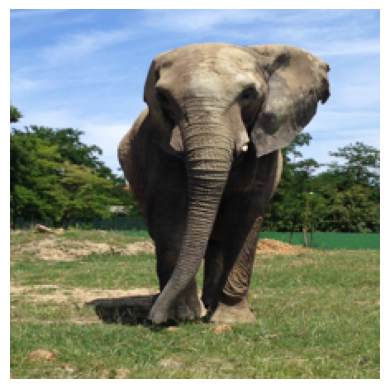

In [8]:
# --- Esecuzione ---
model = carica_modello_vgg()
x, img = ottieni_e_processa_immagine(IMMAGINE_URL)
risultati = classifica_immagine(model, x)

print(f"[4/4] Top-{TOP_N} predizioni:")
for i, (_, etichetta, prob) in enumerate(risultati, start=1):
    print(f"{i}. {etichetta}: {prob:.2%}")

plt.imshow(img)
plt.axis("off")
plt.show()